# F24: Endelig volum i 1D -- kildeledd og randbetingelser med kjent fluks

Denne notatboken hører til **F24** og kompendiets §3.5: eksempelet «Varmeledning med internt kildeledd» og bemerkningen «Randbetingelse med kjent fluks». Den bygger videre på **F23**.

I F23 hadde vi ingen varmekilde, og begge endene hadde kjent temperatur. Nå utvider vi med

* **kildeledd** -- varme som produseres (eller forsvinner) inne i materialet, skrevet på lineær form
$$\overline S\,\Delta V = S^u + S_P\,T_P ,$$
* **randbetingelser med kjent fluks** (Neumann) -- for eksempel en isolert ende.

Koden er skrevet på samme måte som i øvingene og i F23. Alt passer inn i den samme ligningen:
$$
a_P T_P = a_W T_W + a_E T_E + S^u, \qquad a_P = a_W + a_E - S_P .
$$

In [1]:
import numpy as np
import numpy.linalg as la
import matplotlib.pyplot as plt

## 1. Eksempel: plate med jevn varmeproduksjon

Fra kompendiet: en plate med tykkelse $R = 2$ cm, varmeledningsevne $k = 0.5$ W/(m K) og jevn varmeproduksjon $q = 1000$ kW/m$^3$. Flatene holdes på $T_V = 100\,^\circ$C og $T_H = 200\,^\circ$C. Vi ser på et tverrsnitt med areal $A = 1$ m$^2$, og ligningen er
$$
\frac{d}{dx}\left(k\frac{dT}{dx}\right) + q = 0 .
$$
Den analytiske løsningen er
$$
T(x) = \left(\frac{T_H - T_V}{R} + \frac{q}{2k}(R-x)\right)x + T_V .
$$

Vi setter opp punktene `x` akkurat som i F23: randpunktene først og sist, og nodene midt i hvert kontrollvolum. Matrisen `L` og randleddene i `F` er da de samme som i F23. Det eneste nye er **kildeleddet**: integrert over et kontrollvolum (volum $A\,\delta x$) gir det $\overline S\,\Delta V = q\,A\,\delta x$. Det er konstant, så $S^u = qA\delta x$ legges til i `F` for *alle* nodene, og $S_P = 0$.

In [2]:
R = 0.02         # tykkelse på platen [m]
k = 0.5          # varmeledningsevne [W/(m K)]
A = 1.0          # areal [m^2]
kA = k * A
q = 1e6          # varmeproduksjon [W/m^3]
a = 100          # T_V [grader C]
b = 200          # T_H [grader C]

def u_eksakt(x):
    return ((b - a) / R + q / (2 * k) * (R - x)) * x + a

# Rutenettgenerering
m = 5
deltax = R / m
x = np.zeros(m + 2)
x[1:-1] = deltax / 2 + deltax * np.arange(m)   # nodene, midt i hvert kontrollvolum
x[-1] = R
dx = x[1:] - x[:-1]

# Diskretisering
koeff_diag  = kA * (1 / dx[:-1] + 1 / dx[1:])
koeff_over  = -kA / dx[1:-1]
koeff_under = -kA / dx[1:-1]
L = np.diag(koeff_over, 1) + np.diag(koeff_under, -1) + np.diag(koeff_diag, 0)

F = q * A * deltax * np.ones(m)   # kildeleddet S^u = q*A*deltax i alle nodene
F[0]  += kA * 1 / dx[0] * a       # kjent randtemperatur til venstre
F[-1] += kA * 1 / dx[-1] * b      # kjent randtemperatur til høyre

print("L =\n", L)
print("F =", F)

# Løsning til lineært system
u = la.solve(L, F)
print("\nNumerisk:", u)
print("Eksakt:  ", u_eksakt(x[1:-1]))
print("Avvik:   ", u - u_eksakt(x[1:-1]))

L =
 [[ 375. -125.    0.    0.    0.]
 [-125.  250. -125.    0.    0.]
 [   0. -125.  250. -125.    0.]
 [   0.    0. -125.  250. -125.]
 [   0.    0.    0. -125.  375.]]
F = [29000.  4000.  4000.  4000. 54000.]

Numerisk: [150. 218. 254. 258. 230.]
Eksakt:   [146. 214. 250. 254. 226.]
Avvik:    [4. 4. 4. 4. 4.]


Matrisen og høyresiden er de samme som i kompendiet, og løsningen er $150, 218, 254, 258, 230$. Avviket fra den eksakte løsningen er **nøyaktig $4\,^\circ$C i alle nodene**.

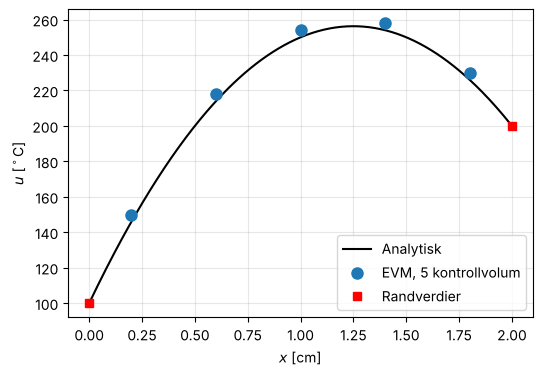

In [3]:
xx = np.linspace(0, R, 300)
plt.figure(figsize=(6, 4))
plt.plot(xx * 100, u_eksakt(xx), "k-", label="Analytisk")
plt.plot(x[1:-1] * 100, u, "o", ms=8, label="EVM, 5 kontrollvolum")
plt.plot([0, R * 100], [a, b], "rs", label="Randverdier")
plt.xlabel("$x$ [cm]"); plt.ylabel(r"$u$ [$^\circ$C]")
plt.legend(); plt.grid(alpha=0.3)
plt.show()

## 2. En generell 1D-løser

For å kunne prøve ut mange varianter samler vi oppsettet i én funksjon. Den bygger `L` og `F` akkurat som over. Det nye er at kilde og randbetingelser kan velges:

* **Kildeleddet:** Er kilden per volumenhet $s(x,u) = s_u(x) + s_p(x)\,u$, blir bidraget fra kontrollvolumet rundt en node
$$S^u = s_u\,A\,\delta x \;\;(\text{legges til i } F), \qquad S_P = s_p\,A\,\delta x \;\;(\text{trekkes fra diagonalen}),$$
  siden $a_P = a_W + a_E - S_P$. En konstant varmeproduksjon $q$ gir $s_u = q$, $s_p = 0$.
* **Rand med kjent temperatur** (som i F23): randpunktet er en nabo i avstand `dx[0]`; leddet `kA/dx[0]*a` går i `F`.
* **Rand med kjent fluks** $q_B$ (varme *inn* per flateenhet, W/m$^2$): da er fluksen gjennom randflaten kjent, så koblingen til randpunktet fjernes fra diagonalen, og $q_B A$ legges til i `F`. En isolert rand er $q_B = 0$.

In [4]:
def evm_1d(R, m, kA, A, venstre, hoyre, kilde=None):
    '''Endelig volum-metode for  d/dx(kA du/dx) + A*s(x,u) = 0  på [0, R].

    venstre, hoyre: randbetingelser, enten ("T", verdi) for kjent temperatur,
                    eller ("fluks", q_B) for kjent varmefluks q_B INN i området [W/m^2].
    kilde:          funksjon x -> (s_u, s_p), der kilden per volumenhet er
                    s = s_u + s_p*u  [W/m^3]. Krever s_p <= 0.
    Returnerer (x, u): alle punktene (med randpunktene) og løsningen i nodene.'''
    # Rutenettgenerering
    deltax = R / m
    x = np.zeros(m + 2)
    x[1:-1] = deltax / 2 + deltax * np.arange(m)
    x[-1] = R
    dx = x[1:] - x[:-1]

    # Diskretisering
    koeff_diag  = kA * (1 / dx[:-1] + 1 / dx[1:])
    koeff_over  = -kA / dx[1:-1]
    koeff_under = -kA / dx[1:-1]
    F = np.zeros((m))

    # kildeleddet, integrert over hvert kontrollvolum (volum A*deltax)
    if kilde is not None:
        s_u, s_p = kilde(x[1:-1])
        if np.any(np.asarray(s_p) > 0):
            raise ValueError("s_p må være <= 0 (se avsnitt 5)")
        F += s_u * A * deltax              # S^u
        koeff_diag -= s_p * A * deltax     # a_P = a_W + a_E - S_P

    # randbetingelsene
    for (typ, verdi), i in ((venstre, 0), (hoyre, -1)):
        if typ == "T":
            F[i] += kA * 1 / dx[i] * verdi          # randpunktet som kjent nabo
        elif typ == "fluks":
            koeff_diag[i] -= kA / dx[i]             # ingen kobling til randpunktet
            F[i] += verdi * A                       # kjent fluks inn
        else:
            raise ValueError("randtype må være 'T' eller 'fluks'")

    L = np.diag(koeff_over, 1) + np.diag(koeff_under, -1) + np.diag(koeff_diag, 0)

    # Løsning til lineært system
    u = la.solve(L, F)
    return x, u


# Test: samme plate som over
konstant_kilde = lambda x: (q * np.ones_like(x), np.zeros_like(x))
x5, u5 = evm_1d(R, 5, kA, A, ("T", a), ("T", b), konstant_kilde)
print("u =", u5)

u = [150. 218. 254. 258. 230.]


## 3. Hvor kommer de 4 gradene fra?

Den eksakte løsningen er en **parabel**. For en parabel er sentraldifferansen $\frac{T_E - 2T_P + T_W}{\delta x^2}$ *eksakt*, så ligningene i de indre cellene oppfylles nøyaktig av den eksakte løsningen. Feilen kommer fra **randcellene**: der tilnærmer vi fluksen gjennom randen med en rett linje fra randverdien til første node, over en halv celle. Den linjen treffer ikke parabelen helt, og feilen i randfluksen forskyver hele løsningen med en konstant.

Vi undersøker hvordan avviket avhenger av $\delta x$:

m =    5, deltax =  4.000 mm:  maks avvik = 4.00000 C,  q*deltax^2/(8k) = 4.00000
m =   10, deltax =  2.000 mm:  maks avvik = 1.00000 C,  q*deltax^2/(8k) = 1.00000
m =   20, deltax =  1.000 mm:  maks avvik = 0.25000 C,  q*deltax^2/(8k) = 0.25000
m =   40, deltax =  0.500 mm:  maks avvik = 0.06250 C,  q*deltax^2/(8k) = 0.06250
m =   80, deltax =  0.250 mm:  maks avvik = 0.01562 C,  q*deltax^2/(8k) = 0.01562
m =  160, deltax =  0.125 mm:  maks avvik = 0.00391 C,  q*deltax^2/(8k) = 0.00391

Estimert konvergensorden: 2.00


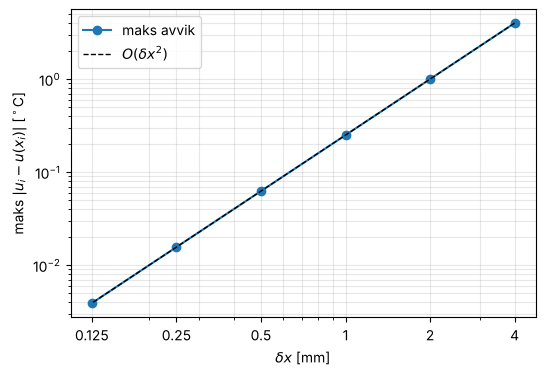

In [5]:
ms = np.array([5, 10, 20, 40, 80, 160])
feil = []
for m_i in ms:
    x_i, u_i = evm_1d(R, m_i, kA, A, ("T", a), ("T", b), konstant_kilde)
    feil.append(np.max(np.abs(u_i - u_eksakt(x_i[1:-1]))))
feil = np.array(feil)
deltaxs = R / ms

for m_i, dx_i, e in zip(ms, deltaxs, feil):
    print(f"m = {m_i:4d}, deltax = {dx_i*1000:6.3f} mm:  maks avvik = {e:.5f} C,"
          f"  q*deltax^2/(8k) = {q*dx_i**2/(8*k):.5f}")

orden = np.polyfit(np.log(deltaxs), np.log(feil), 1)[0]
print(f"\nEstimert konvergensorden: {orden:.2f}")

plt.figure(figsize=(6, 4))
plt.loglog(deltaxs * 1000, feil, "o-", label="maks avvik")
plt.loglog(deltaxs * 1000, feil[0] * (deltaxs / deltaxs[0])**2, "k--", lw=1, label=r"$O(\delta x^2)$")
plt.xlabel(r"$\delta x$ [mm]"); plt.ylabel(r"maks $|u_i - u(x_i)|$ [$^\circ$C]")
plt.legend(); plt.grid(alpha=0.3, which="both")
from matplotlib.ticker import NullFormatter
plt.xticks(deltaxs * 1000, [f"{d:g}" for d in deltaxs * 1000])
plt.gca().xaxis.set_minor_formatter(NullFormatter())
plt.show()

Avviket er nøyaktig $\dfrac{q\,\delta x^2}{8k}$: det firedeles når vi halverer $\delta x$. Metoden er altså **andre ordens**, selv om randcellene er grove -- og med fem kontrollvolum er feilen allerede under 3 %.

## 4. Randbetingelse med kjent fluks

Anta nå at platen er **isolert** på høyre side i stedet for å ha kjent temperatur. Da går ingen varme ut gjennom høyre flate, og fluksen der er kjent: $q_B = 0$. Mer generelt kan vi la en kjent varmefluks $q_B$ (W/m$^2$) strømme *inn* gjennom høyre flate.

For randcellen kjenner vi da fluksleddet $\left(kA\frac{dT}{dx}\right)_e = q_B A$ direkte -- vi trenger ingen tilnærming i det hele tatt. Koblingen mot øst kuttes ($a_E = 0$), og $S^u \mathrel{+}= q_B A$, mens $S_P$ ikke endres.

Den analytiske løsningen (med $T(0)=T_V$ og $k\,T'(R) = q_B$) er
$$
T(x) = T_V + \frac{qR + q_B}{k}\,x - \frac{q}{2k}\,x^2 .
$$

q_B =       0 W/m^2:  maks avvik = 4.000 C
q_B =   10000 W/m^2:  maks avvik = 4.000 C


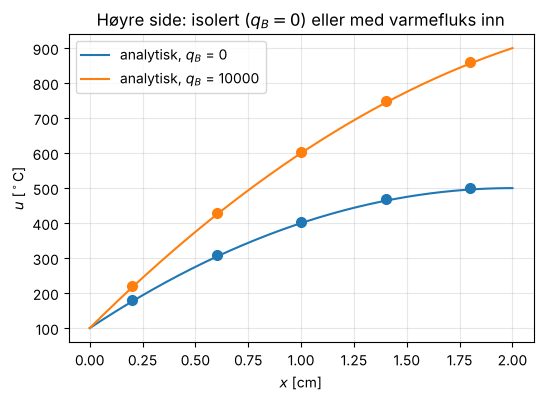

In [6]:
def u_eksakt_fluks(x, q_B):
    return a + (q * R + q_B) / k * x - q / (2 * k) * x**2

plt.figure(figsize=(6, 4))
for q_B, farge in [(0.0, "tab:blue"), (1e4, "tab:orange")]:
    x_f, u_f = evm_1d(R, 5, kA, A, ("T", a), ("fluks", q_B), konstant_kilde)
    print(f"q_B = {q_B:7.0f} W/m^2:  maks avvik = {np.max(np.abs(u_f - u_eksakt_fluks(x_f[1:-1], q_B))):.3f} C")
    plt.plot(xx * 100, u_eksakt_fluks(xx, q_B), "-", color=farge, label=f"analytisk, $q_B$ = {q_B:.0f}")
    plt.plot(x_f[1:-1] * 100, u_f, "o", color=farge, ms=7)
plt.xlabel("$x$ [cm]"); plt.ylabel(r"$u$ [$^\circ$C]")
plt.title("Høyre side: isolert ($q_B=0$) eller med varmefluks inn")
plt.legend(); plt.grid(alpha=0.3)
plt.show()

I koden er forskjellen fra kjent temperatur bare to linjer: koblingen `kA/dx[-1]` til randpunktet trekkes fra diagonalen (det er ingen nabo der), og den kjente fluksen $q_B A$ legges i `F`.

### Energibalansen

All varmen som produseres i platen ($qRA$), pluss det som strømmer inn gjennom høyre side ($q_BA$), må ut gjennom venstre side. Fluksen gjennom venstre randflate regner vi ut på samme måte som da vi satte opp ligningene: lineært over et halvt kontrollvolum.

In [7]:
for q_B in [0.0, 1e4]:
    x_f, u_f = evm_1d(R, 5, kA, A, ("T", a), ("fluks", q_B), konstant_kilde)
    dx_f = x_f[1:] - x_f[:-1]
    Q_ut_venstre = kA * (u_f[0] - a) / dx_f[0]      # varme ut gjennom x = 0 [W]
    print(f"q_B = {q_B:7.0f}:  varme ut til venstre = {Q_ut_venstre:9.1f} W,"
          f"  produsert + inn til høyre = {q*R*A + q_B*A:9.1f} W")

q_B =       0:  varme ut til venstre =   20000.0 W,  produsert + inn til høyre =   20000.0 W
q_B =   10000:  varme ut til venstre =   30000.0 W,  produsert + inn til høyre =   30000.0 W


Energibalansen stemmer **eksakt**, selv med bare fem kontrollvolum og selv om temperaturene har et avvik på $4\,^\circ$C. Det er bevaringsegenskapen fra F23 igjen.

## 5. Hvorfor bør $S_P \le 0$?

Mange kilder avhenger av temperaturen. Et typisk eksempel er en **sluk** -- et varmetap som øker med temperaturen, som kjøling mot omgivelser med temperatur $T_\infty$:
$$
s = -n^2\,(T - T_\infty), \qquad n^2 = \frac{hO}{\kappa A} > 0 .
$$
Dette kan vi linearisere på to måter:

* **(a)** Den $T$-avhengige delen i $S_P$: $\;S^u = n^2 T_\infty A\delta x$, $\;S_P = -n^2 A\delta x$.
* **(b)** Alt i $S^u$, med $T$ fra forrige iterasjon: $\;S^u = -n^2(T_P^{\text{gammel}} - T_\infty)A\delta x$, $\;S_P = 0$.

Begge gir samme løsning *hvis* iterasjonen konvergerer. Men med (a) blir $a_P = a_W + a_E + n^2 A\delta x$ større, og systemet blir mer *diagonaldominant*. Vi tester med Jacobi-iterasjon uten matrise (som i øving 6) på en stav med lengde $1$ m, $kA = 1$, $A=1$, $T_V = 100\,^\circ$C, $T_H = T_\infty = 20\,^\circ$C, og startgjetning $u = 0$.

n^2 =    5: (a) konvergerer etter 274 iterasjoner,  (b) ikke ferdig etter 600 iterasjoner
n^2 =   25: (a) konvergerer etter 125 iterasjoner,  (b) DIVERGERER etter 179 iterasjoner


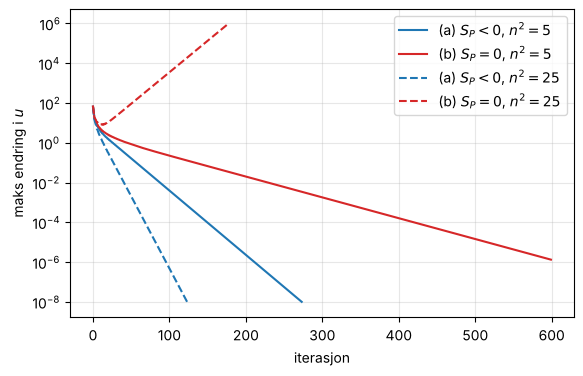

In [8]:
def jacobi(koeff_diag, koeff_over, koeff_under, F_func, u0, maks_it=600, tol=1e-8):
    '''Jacobi-iterasjon for L u = F uten å bygge L:
    u_i = (F_i - koeff_under*u_(i-1) - koeff_over*u_(i+1)) / koeff_diag_i.
    F kan avhenge av u. Returnerer (u, liste med maks endring per iterasjon).'''
    u = u0.copy(); endringer = []
    for _ in range(maks_it):
        nabo = np.zeros_like(u)
        nabo[1:]  += koeff_under * u[:-1]
        nabo[:-1] += koeff_over * u[1:]
        u_ny = (F_func(u) - nabo) / koeff_diag
        endringer.append(np.max(np.abs(u_ny - u)))
        u = u_ny
        if endringer[-1] < tol or endringer[-1] > 1e6:
            break
    return u, endringer

# Oppsett: stav med lengde 1 m, kA = 1, A = 1, m = 10 kontrollvolum
R2, kA2, A2, m2, a2, b2, Tinf = 1.0, 1.0, 1.0, 10, 100.0, 20.0, 20.0
deltax2 = R2 / m2
x2 = np.zeros(m2 + 2); x2[1:-1] = deltax2 / 2 + deltax2 * np.arange(m2); x2[-1] = R2
dx2 = x2[1:] - x2[:-1]
koeff_diag2  = kA2 * (1 / dx2[:-1] + 1 / dx2[1:])
koeff_over2  = -kA2 / dx2[1:-1]
koeff_under2 = -kA2 / dx2[1:-1]
F_rand = np.zeros(m2); F_rand[0] = kA2 / dx2[0] * a2; F_rand[-1] = kA2 / dx2[-1] * b2

plt.figure(figsize=(6.5, 4))
for n2, stil in [(5.0, "-"), (25.0, "--")]:
    # (a): sluk i S_P  ->  n2*A*deltax legges til diagonalen, n2*Tinf*A*deltax i F
    _, e_a = jacobi(koeff_diag2 + n2 * A2 * deltax2, koeff_over2, koeff_under2,
                    lambda u: F_rand + n2 * Tinf * A2 * deltax2, np.zeros(m2))
    # (b): alt i S^u, med u fra forrige iterasjon
    _, e_b = jacobi(koeff_diag2, koeff_over2, koeff_under2,
                    lambda u: F_rand - n2 * (u - Tinf) * A2 * deltax2, np.zeros(m2))
    plt.semilogy(e_a, "tab:blue", ls=stil, label=rf"(a) $S_P<0$, $n^2={n2:.0f}$")
    plt.semilogy(e_b, "tab:red", ls=stil, label=rf"(b) $S_P=0$, $n^2={n2:.0f}$")
    status_b = "DIVERGERER" if e_b[-1] > 1 else ("konvergerer" if e_b[-1] < 1e-8 else "ikke ferdig")
    print(f"n^2 = {n2:4.0f}: (a) konvergerer etter {len(e_a)} iterasjoner,  (b) {status_b} etter {len(e_b)} iterasjoner")
plt.xlabel("iterasjon"); plt.ylabel("maks endring i $u$")
plt.legend(); plt.grid(alpha=0.3, which="both")
plt.show()

Med en svak sluk ($n^2 = 5$) konvergerer (a), mens (b) går mye langsommere. Med en sterkere sluk ($n^2 = 25$) **divergerer** variant (b): feilen vokser som et sagtannmønster -- akkurat som ustabiliteten i F21. Variant (a) konvergerer, og raskere enn med $n^2=5$. Tommelfingerregelen er derfor:

> Legg den delen av kilden som avhenger av $T$, og som *minker* når $T$ øker, i $S_P$. Da er $S_P \le 0$, $a_P \ge a_W + a_E$, og systemet er diagonaldominant.

Et positivt $S_P$ kan i verste fall gjøre $a_P$ negativ, og da gir ligningen fysisk meningsløse løsninger.

## 6. Ribben -- øving 7

Kompendiets tredje eksempel, kjøling av en sirkulær ribbe, har nettopp en slik sluk: $-n^2(T - T_\infty)$, og en **isolert** ende. Det er tema for øving 7 (`EVM_oppgave.ipynb`), der dere setter opp `koeff_diag`, `koeff_over`, `koeff_under` og `F` selv -- på samme måte som i avsnitt 1. Med funksjonen `evm_1d` kan dere etterpå sjekke svaret: en sluk med $s_p < 0$, kjent temperatur i den ene enden og kjent fluks ($q_B = 0$) i den andre. (`evm_1d` løser $\frac{d}{dx}(kA\,u') + A\,s = 0$; ribbeligningen er delt på $kA$, så der er $kA = A = 1$.)

## Prøv selv

1. **Variabel kilde.** La varmeproduksjonen variere, $q(x) = q_0\sin(\pi x/R)$, med $T=0$ i begge ender. Vis at $T(x) = \frac{q_0R^2}{k\pi^2}\sin(\pi x/R)$ er den eksakte løsningen, og sjekk konvergensordenen.
2. **Fluks ut.** Hva skjer med temperaturprofilen i avsnitt 4 hvis $q_B$ er *negativ* (varme trekkes ut på høyre side)? Sjekk energibalansen.
3. **Begge ender isolert.** Prøv `evm_1d` med `("fluks", 0)` i begge ender og en konstant kilde. Hva skjer -- og hvorfor er det fysisk rimelig? (Hint: hvor skal varmen gjøre av seg?)
4. **Feilen i randcellene.** Vis at feilen i avsnitt 3 er $q\,\delta x^2/(8k)$. (Hint: sett den eksakte parabelen inn i ligningen for venstre randcelle.)

## Oppsummering

* Kildeleddet integreres over kontrollvolumet og skrives som $S^u + S_P T_P$. Konstante kilder går i $S^u$; temperaturavhengige sluk går i $S_P \le 0$.
* Kjent temperatur på randen: randpunktet er en nabo i avstand `dx[0]` $=\delta x/2$, og leddet `kA/dx[0]*a` går i `F` (det samme som kompendiets $S^u$ og $S_P$). Kjent fluks: ingen kobling til randpunktet, og $q_BA$ i `F`; isolert rand bidrar ikke.
* Feilen i plate-eksempelet kommer fra randcellene og er $O(\delta x^2)$.
* Energibalansen er oppfylt eksakt, uansett gitter.